In [1]:
import numpy as np
import pandas as pd 

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('weight-height.csv')

In [4]:
df.head(3)

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856


In [5]:
df.shape

(10000, 3)

In [7]:
df['Height'].describe()

count    10000.000000
mean        66.367560
std          3.847528
min         54.263133
25%         63.505620
50%         66.318070
75%         69.174262
max         78.998742
Name: Height, dtype: float64

C:\Users\dell\AppData\Local\Temp\ipykernel_9036\813155145.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Height'], kde=True)


<Axes: xlabel='Height', ylabel='Density'>

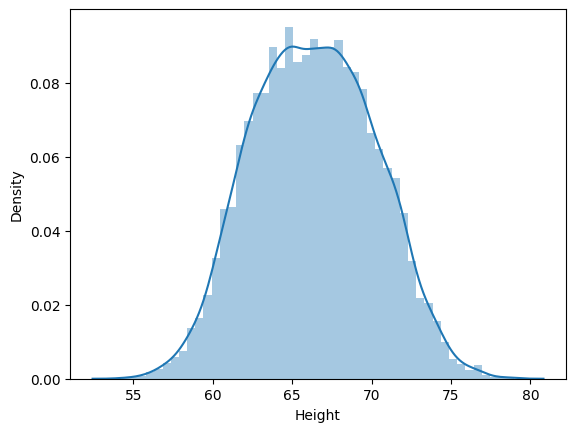

In [8]:
sns.distplot(df['Height'], kde=True)

<Axes: xlabel='Height'>

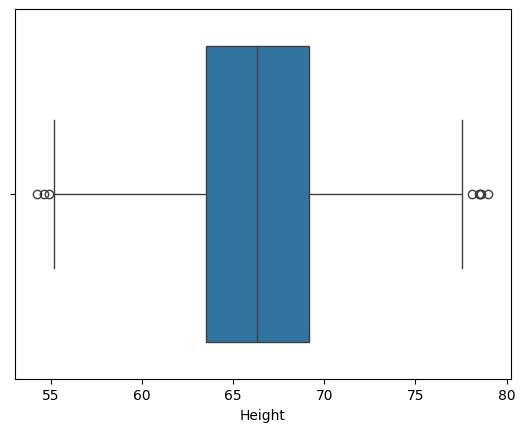

In [9]:
sns.boxplot(df['Height'], orient='h')

In [10]:
upper = df['Height'].quantile(0.99)
lower = df['Height'].quantile(0.01)

In [11]:
upper

74.7857900583366

In [12]:
lower

58.13441158671655

In [13]:
df[(df['Height']>=upper) | (df['Height']<=lower)]

,Gender,Height,Weight
23,Male,75.205974,228.761781
190,Male,76.709835,235.035419
197,Male,75.944460,231.924749
202,Male,75.140821,224.124271
215,Male,74.795375,232.635403
...,...,...,...
9761,Female,56.975279,90.341784
9825,Female,55.979198,85.417534
9895,Female,57.740192,93.652957
9904,Female,57.028857,101.202551


In [14]:
df[(df['Height']>=upper) | (df['Height']<=lower)].shape

(200, 3)

In [15]:
new_df=df[(df['Height']<=upper) & (df['Height']>=lower)]

<Axes: xlabel='Height'>

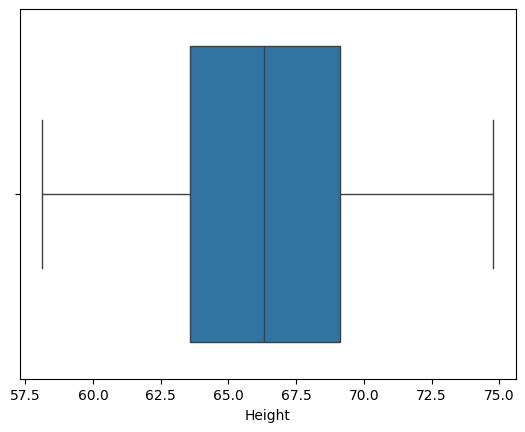

In [17]:
sns.boxplot(new_df['Height'], orient='h')

## Capping

In [18]:
new_df_cap = df.copy()

In [20]:
new_df_cap['Height'] = np.where(new_df_cap['Height']>upper, upper, 
                                np.where(new_df_cap['Height']<lower, lower, new_df_cap['Height']))

<Axes: xlabel='Height'>

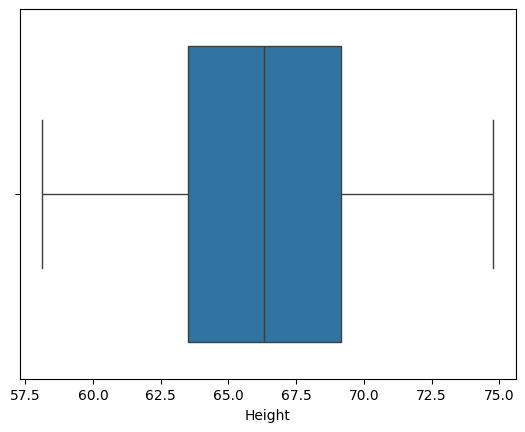

In [21]:
sns.boxplot(new_df_cap['Height'], orient='h')